In [60]:
import numpy as np
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
import pandas as pd
import glob 
import os
import pickle
from pathlib import Path
import time
import pandas as pd

import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import glob 
import pywt #PyWavelets package
import matplotlib.colors as colors
from matplotlib.colors import LogNorm



from data_process import select_df,read_and_process_data ,fac_decompose_dB

In [61]:
with open(Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice-location-ready/"+"cassini_enis_2004_2017_60s.pkl"), "rb") as f:
    cassini_location = pickle.load(f)

In [62]:
def merge_ICW_with_location(labels_df, cassini_location, tolerance='5min'):
    labels = labels_df.copy()
    loc = cassini_location.copy()

    labels['interval_start'] = pd.to_datetime(labels['interval_start']).dt.tz_localize(None)
    labels['interval_end'] = pd.to_datetime(labels['interval_end']).dt.tz_localize(None)
    loc['utc'] = pd.to_datetime(loc['utc']).dt.tz_localize(None)

    # Use interval midpoint as representative time
    labels['time'] = labels['interval_start'] + (
        labels['interval_end'] - labels['interval_start']
    ) / 2

    labels = labels.sort_values('time')
    loc = loc.sort_values('utc')

    # keep_cols = [
    #     'utc', 'x_ksm_Rs', 'y_ksm_Rs', 'z_ksm_Rs',
    #     'r_Rs', 'lat_deg', 'lon_deg'
    # ]
    # keep_cols = [c for c in keep_cols if c in loc.columns]

    merged = pd.merge_asof(
        labels,
        loc,
        left_on='time',
        right_on='utc',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    # return merged.dropna(subset=['r_Rs']).reset_index(drop=True)
    return merged.reset_index(drop=True)
    

# prep

## 1D

In [63]:
def one_d_occurrence_statistics(
    df,
    x_col,
    flag_col='is_ICW',
    bins=None,
    x_range=None,
    min_samples=1
):
    """
    Generic 1D occurrence statistics.

    Occurrence fraction = number of flagged intervals / total intervals in each bin.

    Returns columns:
        bin
        n_total
        n_wave
        x_mean
        occurrence_fraction
        occurrence_percent
    """

    d = df.dropna(subset=[x_col, flag_col]).copy()
    d[flag_col] = d[flag_col].astype(bool)

    if x_range is not None:
        d = d[
            (d[x_col] >= x_range[0]) &
            (d[x_col] <= x_range[1])
        ].copy()

    if bins is None:
        bins = np.linspace(d[x_col].min(), d[x_col].max(), 50)

    d['bin'] = pd.cut(d[x_col], bins=bins, include_lowest=True)

    stat = d.groupby('bin', observed=True).agg(
        n_total=(flag_col, 'size'),
        n_wave=(flag_col, 'sum'),
        x_mean=(x_col, 'mean')
    ).reset_index()

    stat['occurrence_fraction'] = stat['n_wave'] / stat['n_total']
    stat['occurrence_percent'] = 100 * stat['occurrence_fraction']

    stat.loc[
        stat['n_total'] < min_samples,
        ['occurrence_fraction', 'occurrence_percent']
    ] = np.nan

    return stat

In [64]:
def plot_one_d_occurrence(
    stat,
    x_label,
    title,
    y_mode='fraction',
    xlim=None,
    xticks=None,
    ax=None,
    marker='o'
):
    """
    Plot 1D occurrence rate from one_d_occurrence_statistics().
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    else:
        fig = ax.figure

    if y_mode == 'percent':
        y_col = 'occurrence_percent'
        y_label = 'ICW Occurrence Rate (%)'
    else:
        y_col = 'occurrence_fraction'
        y_label = 'ICW Fraction'

    ax.plot(
        stat['x_mean'],
        stat[y_col],
        marker=marker
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)

    if xlim is not None:
        ax.set_xlim(*xlim)

    if xticks is not None:
        ax.set_xticks(xticks)

    ax.grid(True, alpha=0.3)

    return fig, ax

In [65]:
def one_d_sample_statistics(
    df,
    x_col,
    bins=None,
    x_range=None,
    min_samples=1
):
    """
    Generic 1D sample-number statistics.

    Returns columns:
        bin
        n_total
        x_mean
    """

    d = df.dropna(subset=[x_col]).copy()

    if x_range is not None:
        d = d[
            (d[x_col] >= x_range[0]) &
            (d[x_col] <= x_range[1])
        ].copy()

    if bins is None:
        bins = np.linspace(d[x_col].min(), d[x_col].max(), 50)

    d['bin'] = pd.cut(d[x_col], bins=bins, include_lowest=True)

    stat = d.groupby('bin', observed=True).agg(
        n_total=(x_col, 'size'),
        x_mean=(x_col, 'mean')
    ).reset_index()

    stat.loc[stat['n_total'] < min_samples, 'n_total'] = np.nan

    return stat



In [66]:
def plot_one_d_samples(
    stat,
    x_label,
    title,
    xlim=None,
    xticks=None,
    ax=None,
    marker='o',
    log_y=False
):
    """
    Plot 1D sample numbers from one_d_sample_statistics().
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    else:
        fig = ax.figure

    ax.plot(
        stat['x_mean'],
        stat['n_total'],
        marker=marker
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel('Number of Samples')
    ax.set_title(title)

    if log_y:
        ax.set_yscale('log')

    if xlim is not None:
        ax.set_xlim(*xlim)

    if xticks is not None:
        ax.set_xticks(xticks)

    ax.grid(True, alpha=0.3)

    return fig, ax

## 2D

In [67]:
def make_wave_occurrence_maps(
    df,
    L_col='L_approx',
    MLT_col='MLT_hr',
    MLAT_col='MLAT_approx_deg',
    flag_col='is_ICW',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.25,
    dMLT=0.5,
    dMLAT=2.5,
    min_samples=10
):
    """
    Make Long et al.-style occurrence maps:
        L-MLT:  dL x dMLT
        L-MLAT: dL x dMLAT

    Returns a dictionary containing occurrence maps and sample-number maps.
    """

    d = df.copy()

    needed = [L_col, MLT_col, MLAT_col, flag_col]
    missing = [c for c in needed if c not in d.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    d = d[needed].replace([np.inf, -np.inf], np.nan).dropna()
    d[flag_col] = d[flag_col].astype(bool)

    # Clean ranges
    d = d[
        (d[L_col] >= L_range[0]) &
        (d[L_col] <= L_range[1]) &
        (d[MLT_col] >= 0) &
        (d[MLT_col] < 24) &
        (d[MLAT_col] >= MLAT_range[0]) &
        (d[MLAT_col] <= MLAT_range[1])
    ].copy()

    L_edges = np.arange(L_range[0], L_range[1] + dL, dL)
    MLT_edges = np.arange(0, 24 + dMLT, dMLT)
    MLAT_edges = np.arange(MLAT_range[0], MLAT_range[1] + dMLAT, dMLAT)

    # -----------------------
    # L-MLT map
    # -----------------------
    total_L_MLT, _, _ = np.histogram2d(
        d[L_col],
        d[MLT_col],
        bins=[L_edges, MLT_edges]
    )

    wave_L_MLT, _, _ = np.histogram2d(
        d.loc[d[flag_col], L_col],
        d.loc[d[flag_col], MLT_col],
        bins=[L_edges, MLT_edges]
    )

    occ_L_MLT = 100.0 * wave_L_MLT / total_L_MLT
    occ_L_MLT[total_L_MLT < min_samples] = np.nan

    # -----------------------
    # L-MLAT map
    # -----------------------
    total_L_MLAT, _, _ = np.histogram2d(
        d[L_col],
        d[MLAT_col],
        bins=[L_edges, MLAT_edges]
    )

    wave_L_MLAT, _, _ = np.histogram2d(
        d.loc[d[flag_col], L_col],
        d.loc[d[flag_col], MLAT_col],
        bins=[L_edges, MLAT_edges]
    )

    occ_L_MLAT = 100.0 * wave_L_MLAT / total_L_MLAT
    occ_L_MLAT[total_L_MLAT < min_samples] = np.nan

    return {
        'L_edges': L_edges,
        'MLT_edges': MLT_edges,
        'MLAT_edges': MLAT_edges,

        'occ_L_MLT': occ_L_MLT,
        'Ns_L_MLT': total_L_MLT,

        'occ_L_MLAT': occ_L_MLAT,
        'Ns_L_MLAT': total_L_MLAT,

        'clean_df': d
    }

In [68]:
def plot_L_MLT_occurrence(maps, title='ICW Occurrence Rate in L-MLT'):
    L_edges = maps['L_edges']
    MLT_edges = maps['MLT_edges']
    occ = maps['occ_L_MLT']

    theta_edges = 2 * np.pi * MLT_edges / 24.0

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        occ,
        shading='auto',
        vmin=0,
        vmax=100
    )

    ax.set_theta_zero_location('E')   # 00 MLT on right
    ax.set_theta_direction(1)         # 06 top, 12 left, 18 bottom

    ax.set_xticks(2 * np.pi * np.array([0, 6, 12, 18]) / 24)
    ax.set_xticklabels(['00', '06', '12', '18'])

    ax.set_ylabel('L shell')
    ax.set_title(title)

    # Enceladus and Dione reference circles
    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, np.full_like(theta, 4.0), c='C3',linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), c='C1',linestyle='--', linewidth=1.5, label='Dione L~6.2')

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Occurrence Rate (%)')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.15))

    plt.show()

In [69]:
def plot_L_MLAT_occurrence(
    maps,
    title='ICW Occurrence Rate in L-MLAT',
    vmin=0,
    vmax=100
):
    L_edges = maps['L_edges']
    MLAT_edges = maps['MLAT_edges']
    occ = maps['occ_L_MLAT']

    theta_edges = np.radians(MLAT_edges)

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )


    
    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        occ,
        shading='auto',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_thetamin(-90)
    ax.set_thetamax(90)

    # ax.set_theta_zero_location('W')
    # ax.set_theta_direction(-1)

    mlat_ticks = np.array([-60, -40, -20, 0, 20, 40, 60])
    theta_ticks = np.radians(mlat_ticks)

    ax.set_xticks(theta_ticks)
    ax.set_xticklabels([f'{x:g}°' for x in mlat_ticks])

    ax.set_xlabel('MLAT')
    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(-0.5*np.pi, 0.5*np.pi, 400)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Occurrence Rate (%)')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.1))

    plt.show()

In [70]:
def plot_L_MLT_samples(
    maps,
    title='Number of Samples in L-MLT',
    vmin=10,
    vmax=None
):
    L_edges = maps['L_edges']
    MLT_edges = maps['MLT_edges']
    Ns = maps['Ns_L_MLT'].copy()

    Ns[Ns < 1] = np.nan

    if vmax is None:
        vmax = np.nanmax(Ns)

    theta_edges = 2 * np.pi * MLT_edges / 24.0

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        Ns,
        shading='auto',
        norm=LogNorm(vmin=vmin, vmax=vmax)
    )

    ax.set_theta_zero_location('E')   # 00 MLT on right
    ax.set_theta_direction(1)         # 06 top, 12 left, 18 bottom

    ax.set_xticks(2 * np.pi * np.array([0, 6, 12, 18]) / 24)
    ax.set_xticklabels(['00', '06', '12', '18'])

    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Number of Samples')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.15))

    plt.show()

In [71]:
def plot_L_MLAT_samples(
    maps,
    title='Number of Samples in L-MLAT',
    vmin=10,
    vmax=None
):
    L_edges = maps['L_edges']
    MLAT_edges = maps['MLAT_edges']
    Ns = maps['Ns_L_MLAT'].copy()

    Ns[Ns < 1] = np.nan

    if vmax is None:
        vmax = np.nanmax(Ns)

    theta_edges = np.radians(MLAT_edges)

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        Ns,
        shading='auto',
        norm=LogNorm(vmin=vmin, vmax=vmax)
    )

    ax.set_thetamin(-90)
    ax.set_thetamax(90)

    mlat_ticks = np.array([-60, -40, -20, 0, 20, 40, 60])
    theta_ticks = np.radians(mlat_ticks)

    ax.set_xticks(theta_ticks)
    ax.set_xticklabels([f'{x:g}°' for x in mlat_ticks])

    ax.set_xlabel('MLAT')
    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(-0.5 * np.pi, 0.5 * np.pi, 400)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Number of Samples')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.1))

    plt.show()

## 3D

In [72]:
def make_3d_occurrence_table(
    df,
    flag_col='is_ICW',
    L_col='L_approx',
    MLT_col='MLT_hr',
    MLAT_col='MLAT_approx_deg',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.25,
    dMLT=0.5,
    dMLAT=2.5,
    min_samples=10
):
    d = df[[L_col, MLT_col, MLAT_col, flag_col]].copy()
    d = d.replace([np.inf, -np.inf], np.nan).dropna()

    d[flag_col] = d[flag_col].astype(bool)

    d = d[
        (d[L_col] >= L_range[0]) &
        (d[L_col] <= L_range[1]) &
        (d[MLT_col] >= 0) &
        (d[MLT_col] < 24) &
        (d[MLAT_col] >= MLAT_range[0]) &
        (d[MLAT_col] <= MLAT_range[1])
    ].copy()

    L_edges = np.arange(L_range[0], L_range[1] + dL, dL)
    MLT_edges = np.arange(0, 24 + dMLT, dMLT)
    MLAT_edges = np.arange(MLAT_range[0], MLAT_range[1] + dMLAT, dMLAT)

    d['L_bin'] = pd.cut(d[L_col], bins=L_edges, include_lowest=True)
    d['MLT_bin'] = pd.cut(d[MLT_col], bins=MLT_edges, include_lowest=True)
    d['MLAT_bin'] = pd.cut(d[MLAT_col], bins=MLAT_edges, include_lowest=True)

    stat = d.groupby(
        ['L_bin', 'MLT_bin', 'MLAT_bin'],
        observed=True
    ).agg(
        n_total=(flag_col, 'size'),
        n_wave=(flag_col, 'sum'),
        L_mean=(L_col, 'mean'),
        MLT_mean=(MLT_col, 'mean'),
        MLAT_mean=(MLAT_col, 'mean')
    ).reset_index()

    stat['occurrence_fraction'] = stat['n_wave'] / stat['n_total']
    stat['occurrence_percent'] = 100 * stat['occurrence_fraction']

    stat = stat[stat['n_total'] >= min_samples].copy()

    theta = 2 * np.pi * stat['MLT_mean'] / 24.0
    mlat_rad = np.radians(stat['MLAT_mean'])

    # Simple magnetospheric 3D display coordinates
    stat['x'] = stat['L_mean'] * np.cos(theta)
    stat['y'] = stat['L_mean'] * np.sin(theta)
    stat['z'] = stat['L_mean'] * np.sin(mlat_rad)

    return stat

In [73]:
def plot_3d_occurrence_plotly_go(
    stat3d,
    color_col='occurrence_percent',
    title='3D ICW Occurrence Rate',
    color_range=(0, 100),
    marker_size=6,
    colorscale='Viridis',
    opacity=0.85
):
    """
    3D occurrence-rate plot using plotly.graph_objects.

    Marker size is fixed.
    Marker color shows occurrence rate.

    Required columns in stat3d:
        x, y, z
        L_mean, MLT_mean, MLAT_mean
        n_total, n_wave
        occurrence_percent
    """

    d = stat3d.copy()

    d = d.replace([np.inf, -np.inf], np.nan).dropna(
        subset=['x', 'y', 'z', color_col]
    )

    hover_text = [
        (
            f"L = {L:.2f}<br>"
            f"MLT = {MLT:.2f} hr<br>"
            f"MLAT = {MLAT:.1f}°<br>"
            f"N total = {Nt}<br>"
            f"N wave = {Nw}<br>"
            f"Occurrence = {Occ:.1f}%"
        )
        for L, MLT, MLAT, Nt, Nw, Occ in zip(
            d['L_mean'],
            d['MLT_mean'],
            d['MLAT_mean'],
            d['n_total'],
            d['n_wave'],
            d[color_col]
        )
    ]

    fig = go.Figure()

    fig.add_trace(
        go.Scatter3d(
            x=d['x'],
            y=d['y'],
            z=d['z'],
            mode='markers',
            text=hover_text,
            hoverinfo='text',
            marker=dict(
                size=marker_size,
                color=d[color_col],
                colorscale=colorscale,
                cmin=color_range[0],
                cmax=color_range[1],
                opacity=opacity,
                colorbar=dict(
                    title='Occurrence Rate (%)'
                )
            ),
            name='Occurrence'
        )
    )

    fig.update_layout(
        title=title,
        width=1500,
        height=600,
        scene=dict(
            xaxis=dict(title='X-like coordinate'),
            yaxis=dict(title='Y-like coordinate'),
            zaxis=dict(title='Z-like coordinate'),
            aspectmode='data'
        )
    )

    return fig

In [74]:
def add_L_shell_ring_go(
    fig,
    L=4.0,
    name='Enceladus L~4',
    z=0,
    line_width=5
):
    theta = np.linspace(0, 2 * np.pi, 500)

    x = L * np.cos(theta)
    y = L * np.sin(theta)
    zz = np.full_like(theta, z)

    fig.add_trace(
        go.Scatter3d(
            x=x,
            y=y,
            z=zz,
            mode='lines',
            name=name,
            line=dict(
                width=line_width,
                dash='dash'
            )
        )
    )

    return fig

# load in events

In [75]:
with open('data/check_wave/ICW_labels_2004_2017.pkl', 'rb') as f:
    labels_df = pickle.load(f)

In [76]:
ICW_loc_df = merge_ICW_with_location(labels_df, cassini_location)

In [77]:
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_enis_km,y_enis_km,z_enis_km,...,saturn_z_enis_km,saturn_x_enis_RE,saturn_y_enis_RE,saturn_z_enis_RE,sun_x_enis_km,sun_y_enis_km,sun_z_enis_km,sun_x_enis_RE,sun_y_enis_RE,sun_z_enis_RE
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,6.010075e+06,-2.329855e+07,-7.124432e+06,...,-2.160279e-13,4.787258e-14,943.991689,-8.572764e-16,1.224916e+09,-7.836272e+07,-5.674773e+08,4.860905e+06,-3.109714e+05,-2.251954e+06
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,5.256121e+06,-2.347501e+07,-7.123562e+06,...,-1.776790e-12,-2.708136e-15,944.130227,-7.050940e-15,1.221787e+09,-1.173608e+08,-5.674816e+08,4.848488e+06,-4.657297e+05,-2.251971e+06
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,4.497248e+06,-2.362729e+07,-7.122686e+06,...,3.064190e-12,5.112154e-14,944.269236,1.215981e-14,1.217418e+09,-1.562280e+08,-5.674858e+08,4.831150e+06,-6.199687e+05,-2.251988e+06
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,3.734231e+06,-2.375526e+07,-7.121804e+06,...,5.276743e-14,-3.544654e-15,944.408574,2.094001e-16,1.211814e+09,-1.949249e+08,-5.674902e+08,4.808914e+06,-7.735321e+05,-2.252005e+06
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,2.967851e+06,-2.385882e+07,-7.120916e+06,...,6.451515e-12,-1.665895e-15,944.548100,2.560193e-14,1.204983e+09,-2.334125e+08,-5.674946e+08,4.781807e+06,-9.262646e+05,-2.252022e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-9.538960e+05,-7.574319e+04,3.139608e+05,...,-3.257067e-13,4.166228e-14,940.335944,-1.292521e-15,1.273147e+09,4.331465e+08,6.761990e+08,5.052303e+06,1.718881e+06,2.683401e+06
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-9.611225e+05,-4.486749e+04,3.143557e+05,...,2.243471e-12,-6.692418e-15,940.382560,8.902896e-15,1.286398e+09,3.920245e+08,6.761952e+08,5.104891e+06,1.555694e+06,2.683385e+06
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-9.673408e+05,-1.384946e+04,3.147472e+05,...,-1.586656e-12,5.224539e-14,940.433491,-6.296419e-15,1.298321e+09,3.505024e+08,6.761910e+08,5.152205e+06,1.390919e+06,2.683369e+06
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,-9.725492e+05,1.727742e+04,3.151350e+05,...,1.395176e-12,5.592884e-16,940.488683,5.536560e-15,1.308903e+09,3.086236e+08,6.761866e+08,5.194198e+06,1.224729e+06,2.683351e+06


In [78]:
# delete the variable r_bin
del r_bins



NameError: name 'r_bins' is not defined

In [ ]:
# Radial distance
# r_bins = np.linspace(0, 20, 300)

r_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='distance_km',
    flag_col='is_ICW',
    # bins=r_bins,
    # x_range=(0, 20),
    min_samples=1
)



In [ ]:
r_stat

,bin,n_total,n_wave,x_mean,occurrence_fraction,occurrence_percent
0,"(346.15900000000005, 514911.465]",32178,16638,3.437736e+05,0.517061,51.706135
1,"(514911.465, 1029476.771]",97369,16836,8.071345e+05,0.172909,17.290924
2,"(1029476.771, 1544042.076]",145630,1765,1.277636e+06,0.012120,1.211976
3,"(1544042.076, 2058607.381]",113722,898,1.797763e+06,0.007896,0.789645
4,"(2058607.381, 2573172.686]",120278,482,2.313886e+06,0.004007,0.400738
5,"(2573172.686, 3087737.991]",82475,209,2.797502e+06,0.002534,0.253410
6,"(3087737.991, 3602303.296]",31386,42,3.302961e+06,0.001338,0.133818
7,"(3602303.296, 4116868.601]",14643,8,3.845783e+06,0.000546,0.054634
8,"(4116868.601, 4631433.906]",7571,13,4.315670e+06,0.001717,0.171708
9,"(4631433.906, 5145999.212]",1792,0,4.815740e+06,0.000000,0.000000


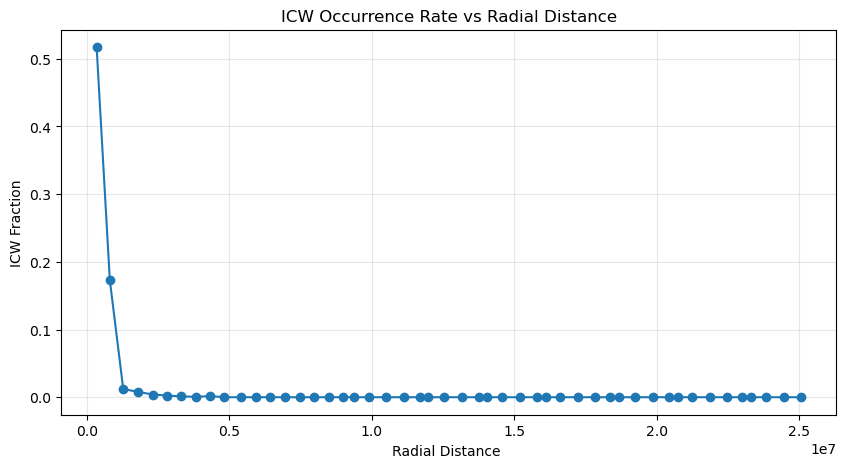

In [ ]:
plot_one_d_occurrence(
    r_stat,
    x_label='Radial Distance ',
    title='ICW Occurrence Rate vs Radial Distance',
    y_mode='fraction',
    # xlim=(0, 20)
)

plt.show()

In [ ]:
60*1e3

60000.0

In [ ]:
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_enis_km,y_enis_km,z_enis_km,...,saturn_z_enis_km,saturn_x_enis_RE,saturn_y_enis_RE,saturn_z_enis_RE,sun_x_enis_km,sun_y_enis_km,sun_z_enis_km,sun_x_enis_RE,sun_y_enis_RE,sun_z_enis_RE
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,-2.329855e+07,-6.010075e+06,-7.124432e+06,...,3.421951e-12,943.991689,-1.002338e-14,1.357953e-14,-7.836272e+07,-1.224916e+09,-5.674773e+08,-3.109714e+05,-4.860905e+06,-2.251954e+06
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,-2.347501e+07,-5.256121e+06,-7.123562e+06,...,-1.776790e-12,944.130227,-1.192336e-14,-7.050940e-15,-1.173608e+08,-1.221787e+09,-5.674816e+08,-4.657297e+05,-4.848488e+06,-2.251971e+06
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,-2.362729e+07,-4.497248e+06,-7.122686e+06,...,2.305288e-12,944.269236,-6.363557e-15,9.148209e-15,-1.562280e+08,-1.217418e+09,-5.674858e+08,-6.199687e+05,-4.831150e+06,-2.251988e+06
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,-2.375526e+07,-3.734231e+06,-7.121804e+06,...,2.954970e-12,944.408574,-6.020744e-15,1.172638e-14,-1.949249e+08,-1.211814e+09,-5.674902e+08,-7.735321e+05,-4.808914e+06,-2.252005e+06
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,-2.385882e+07,-2.967851e+06,-7.120916e+06,...,2.813536e-12,944.548100,1.303487e-15,1.116512e-14,-2.334125e+08,-1.204983e+09,-5.674946e+08,-9.262646e+05,-4.781807e+06,-2.252022e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-7.574319e+04,9.538960e+05,3.139608e+05,...,-3.257067e-13,940.335944,-5.380997e-15,-1.292521e-15,4.331465e+08,-1.273147e+09,6.761990e+08,1.718881e+06,-5.052303e+06,2.683401e+06
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-4.486749e+04,9.611225e+05,3.143557e+05,...,2.243471e-12,940.382560,7.446328e-15,8.902896e-15,3.920245e+08,-1.286398e+09,6.761952e+08,1.555694e+06,-5.104891e+06,2.683385e+06
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-1.384946e+04,9.673408e+05,3.147472e+05,...,2.323338e-13,940.433491,3.437544e-14,9.219839e-16,3.505024e+08,-1.298321e+09,6.761910e+08,1.390919e+06,-5.152205e+06,2.683369e+06
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,1.727742e+04,9.725492e+05,3.151350e+05,...,1.395176e-12,940.488683,-5.592884e-16,5.536560e-15,3.086236e+08,-1.308903e+09,6.761866e+08,1.224729e+06,-5.194198e+06,2.683351e+06


In [ ]:
MLT_bins = np.arange(0, 24 + 0.5, 0.5)

mlt_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='local_time_hr',
    flag_col='is_ICW',
    bins=MLT_bins,
    # x_range=(0, 24),
    min_samples=1
)

In [ ]:
mlt_stat

,bin,n_total,n_wave,x_mean,occurrence_fraction,occurrence_percent
0,"(-0.001, 0.5]",16713,1134,0.250396,0.067851,6.785137
1,"(0.5, 1.0]",16905,1217,0.750961,0.071991,7.199054
2,"(1.0, 1.5]",16938,1404,1.250206,0.082891,8.289054
3,"(1.5, 2.0]",16860,1581,1.749265,0.093772,9.377224
4,"(2.0, 2.5]",16495,1318,2.249272,0.079903,7.990300
5,"(2.5, 3.0]",16054,1164,2.748896,0.072505,7.250529
6,"(3.0, 3.5]",15657,956,3.248664,0.061059,6.105895
7,"(3.5, 4.0]",15469,1072,3.749837,0.069300,6.929989
8,"(4.0, 4.5]",15083,991,4.249119,0.065703,6.570311
9,"(4.5, 5.0]",14801,951,4.748404,0.064252,6.425242


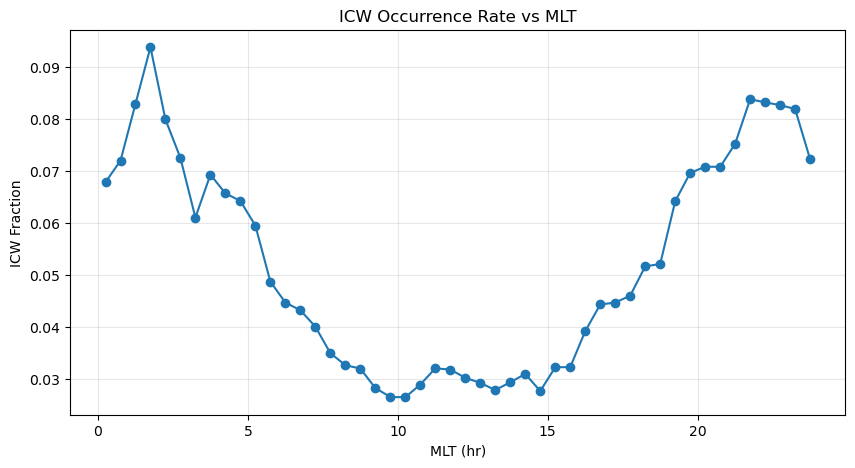

In [ ]:
plot_one_d_occurrence(
    mlt_stat,
    x_label='MLT (hr)',
    title='ICW Occurrence Rate vs MLT',
    y_mode='fraction',
    # xlim=(0, 24),
    # xticks=np.arange(0, 25, 3)
)

plt.show()

In [ ]:
# give me 3d plot distribution of x y z in this coordinate



In [ ]:
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_enis_km,y_enis_km,z_enis_km,...,saturn_z_enis_km,saturn_x_enis_RE,saturn_y_enis_RE,saturn_z_enis_RE,sun_x_enis_km,sun_y_enis_km,sun_z_enis_km,sun_x_enis_RE,sun_y_enis_RE,sun_z_enis_RE
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,-2.329855e+07,-6.010075e+06,-7.124432e+06,...,3.421951e-12,943.991689,-1.002338e-14,1.357953e-14,-7.836272e+07,-1.224916e+09,-5.674773e+08,-3.109714e+05,-4.860905e+06,-2.251954e+06
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,-2.347501e+07,-5.256121e+06,-7.123562e+06,...,-1.776790e-12,944.130227,-1.192336e-14,-7.050940e-15,-1.173608e+08,-1.221787e+09,-5.674816e+08,-4.657297e+05,-4.848488e+06,-2.251971e+06
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,-2.362729e+07,-4.497248e+06,-7.122686e+06,...,2.305288e-12,944.269236,-6.363557e-15,9.148209e-15,-1.562280e+08,-1.217418e+09,-5.674858e+08,-6.199687e+05,-4.831150e+06,-2.251988e+06
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,-2.375526e+07,-3.734231e+06,-7.121804e+06,...,2.954970e-12,944.408574,-6.020744e-15,1.172638e-14,-1.949249e+08,-1.211814e+09,-5.674902e+08,-7.735321e+05,-4.808914e+06,-2.252005e+06
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,-2.385882e+07,-2.967851e+06,-7.120916e+06,...,2.813536e-12,944.548100,1.303487e-15,1.116512e-14,-2.334125e+08,-1.204983e+09,-5.674946e+08,-9.262646e+05,-4.781807e+06,-2.252022e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-7.574319e+04,9.538960e+05,3.139608e+05,...,-3.257067e-13,940.335944,-5.380997e-15,-1.292521e-15,4.331465e+08,-1.273147e+09,6.761990e+08,1.718881e+06,-5.052303e+06,2.683401e+06
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-4.486749e+04,9.611225e+05,3.143557e+05,...,2.243471e-12,940.382560,7.446328e-15,8.902896e-15,3.920245e+08,-1.286398e+09,6.761952e+08,1.555694e+06,-5.104891e+06,2.683385e+06
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-1.384946e+04,9.673408e+05,3.147472e+05,...,2.323338e-13,940.433491,3.437544e-14,9.219839e-16,3.505024e+08,-1.298321e+09,6.761910e+08,1.390919e+06,-5.152205e+06,2.683369e+06
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,1.727742e+04,9.725492e+05,3.151350e+05,...,1.395176e-12,940.488683,-5.592884e-16,5.536560e-15,3.086236e+08,-1.308903e+09,6.761866e+08,1.224729e+06,-5.194198e+06,2.683351e+06


# 3D


In [ ]:
print(ICW_loc_df)

                interval_start            interval_end  is_ICW  \
0      2004-05-14 00:10:24.500 2004-05-14 00:20:24.500   False   
1      2004-05-14 00:20:24.500 2004-05-14 00:30:24.500   False   
2      2004-05-14 00:30:24.500 2004-05-14 00:40:24.500   False   
3      2004-05-14 00:40:24.500 2004-05-14 00:50:24.500   False   
4      2004-05-14 00:50:24.500 2004-05-14 01:00:24.500   False   
...                        ...                     ...     ...   
665804 2017-08-31 22:55:21.500 2017-08-31 23:05:21.500   False   
665805 2017-08-31 23:05:21.500 2017-08-31 23:15:21.500   False   
665806 2017-08-31 23:15:21.500 2017-08-31 23:25:21.500   False   
665807 2017-08-31 23:25:21.500 2017-08-31 23:35:21.500   False   
665808 2017-08-31 23:35:21.500 2017-08-31 23:45:21.500   False   

                                                file_name  \
0       data/_cassini-mag-cal-sec-krtp/04135_04240_00_...   
1       data/_cassini-mag-cal-sec-krtp/04135_04240_00_...   
2       data/_cassini-ma

In [79]:
df=ICW_loc_df

In [81]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ============================================================
# Settings
# ============================================================
R_ENCELADUS_KM = 252.1

n_bins = 36
min_count = 10

# Focus region around Enceladus in Enceladus radii.
# This keeps Enceladus and Saturn visible.
# Set to None to use the full available range.
axis_limit_RE = 2500

# ============================================================
# Coordinates: Cassini in Enceladus-centered ENIS frame
# ============================================================
d = df[
    [
        "x_enis_km",
        "y_enis_km",
        "z_enis_km",
        "saturn_x_enis_km",
        "saturn_y_enis_km",
        "saturn_z_enis_km",
        "is_ICW",
    ]
].dropna().copy()

# Convert Cassini position to Enceladus radii
d["x_RE"] = d["x_enis_km"] / R_ENCELADUS_KM
d["y_RE"] = d["y_enis_km"] / R_ENCELADUS_KM
d["z_RE"] = d["z_enis_km"] / R_ENCELADUS_KM

# Convert Saturn position to Enceladus radii
d["saturn_x_RE"] = d["saturn_x_enis_km"] / R_ENCELADUS_KM
d["saturn_y_RE"] = d["saturn_y_enis_km"] / R_ENCELADUS_KM
d["saturn_z_RE"] = d["saturn_z_enis_km"] / R_ENCELADUS_KM

d["is_ICW"] = d["is_ICW"].astype(int)

# Saturn is effectively fixed in this frame; use median for robustness
saturn_pos = np.array(
    [
        d["saturn_x_RE"].median(),
        d["saturn_y_RE"].median(),
        d["saturn_z_RE"].median(),
    ]
)

# ============================================================
# Optional spatial focus around Enceladus
# ============================================================
if axis_limit_RE is not None:
    keep = (
        d["x_RE"].between(-axis_limit_RE, axis_limit_RE)
        & d["y_RE"].between(-axis_limit_RE, axis_limit_RE)
        & d["z_RE"].between(-axis_limit_RE, axis_limit_RE)
    )
    d_plot = d.loc[keep].copy()

    bin_edges = [
        np.linspace(-axis_limit_RE, axis_limit_RE, n_bins + 1),
        np.linspace(-axis_limit_RE, axis_limit_RE, n_bins + 1),
        np.linspace(-axis_limit_RE, axis_limit_RE, n_bins + 1),
    ]
else:
    d_plot = d.copy()

    bin_edges = [
        np.linspace(d_plot["x_RE"].min(), d_plot["x_RE"].max(), n_bins + 1),
        np.linspace(d_plot["y_RE"].min(), d_plot["y_RE"].max(), n_bins + 1),
        np.linspace(d_plot["z_RE"].min(), d_plot["z_RE"].max(), n_bins + 1),
    ]

# ============================================================
# 3D histogram binning
# ============================================================
coords = d_plot[["x_RE", "y_RE", "z_RE"]].to_numpy()
icw = d_plot["is_ICW"].to_numpy()

# Total samples per bin
total_counts, edges = np.histogramdd(
    coords,
    bins=bin_edges
)

# ICW samples per bin
icw_counts, _ = np.histogramdd(
    coords,
    bins=bin_edges,
    weights=icw
)

with np.errstate(divide="ignore", invalid="ignore"):
    occurrence_rate = icw_counts / total_counts

# Bin centers
x_centers = 0.5 * (edges[0][:-1] + edges[0][1:])
y_centers = 0.5 * (edges[1][:-1] + edges[1][1:])
z_centers = 0.5 * (edges[2][:-1] + edges[2][1:])

X, Y, Z = np.meshgrid(
    x_centers,
    y_centers,
    z_centers,
    indexing="ij"
)

# Keep only sufficiently sampled bins
mask = total_counts >= min_count

plot_df = pd.DataFrame(
    {
        "x_RE": X[mask],
        "y_RE": Y[mask],
        "z_RE": Z[mask],
        "n_total": total_counts[mask].astype(int),
        "n_ICW": icw_counts[mask].astype(int),
        "occurrence_rate": occurrence_rate[mask],
    }
)

# Marker size scaled by sampling density
plot_df["marker_size"] = 3 + 9 * np.sqrt(
    plot_df["n_total"] / plot_df["n_total"].max()
)

plot_df["hover"] = (
    "ICW occurrence rate: "
    + plot_df["occurrence_rate"].map("{:.2%}".format)
    + "<br>Total samples: "
    + plot_df["n_total"].astype(str)
    + "<br>ICW samples: "
    + plot_df["n_ICW"].astype(str)
    + "<br>x: "
    + plot_df["x_RE"].map("{:.1f}".format)
    + " R<sub>E</sub>"
    + "<br>y: "
    + plot_df["y_RE"].map("{:.1f}".format)
    + " R<sub>E</sub>"
    + "<br>z: "
    + plot_df["z_RE"].map("{:.1f}".format)
    + " R<sub>E</sub>"
)

# ============================================================
# Optional Saturn sphere
# ============================================================
def make_sphere(center, radius, n_theta=40, n_phi=20):
    theta = np.linspace(0, 2 * np.pi, n_theta)
    phi = np.linspace(0, np.pi, n_phi)

    theta, phi = np.meshgrid(theta, phi)

    xs = center[0] + radius * np.sin(phi) * np.cos(theta)
    ys = center[1] + radius * np.sin(phi) * np.sin(theta)
    zs = center[2] + radius * np.cos(phi)

    return xs, ys, zs


saturn_radius_RE = 60268.0 / R_ENCELADUS_KM
sat_x, sat_y, sat_z = make_sphere(
    center=saturn_pos,
    radius=saturn_radius_RE
)

# ============================================================
# Plotly graph_objects figure
# ============================================================
fig = go.Figure()

# ICW occurrence-rate bins
fig.add_trace(
    go.Scatter3d(
        x=plot_df["x_RE"],
        y=plot_df["y_RE"],
        z=plot_df["z_RE"],
        mode="markers",
        marker=dict(
            size=plot_df["marker_size"],
            color=plot_df["occurrence_rate"],
            colorscale="Viridis",
            cmin=0,
            cmax=1,
            opacity=0.78,
            colorbar=dict(
                title="ICW<br>occurrence<br>rate",
                tickformat=".0%",
            ),
        ),
        text=plot_df["hover"],
        hoverinfo="text",
        name="ICW occurrence rate",
    )
)

# Enceladus at origin
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],
        mode="markers+text",
        marker=dict(
            size=8,
            color="black",
        ),
        text=["Enceladus"],
        textposition="top center",
        hoverinfo="text",
        name="Enceladus",
    )
)

# Saturn center
fig.add_trace(
    go.Scatter3d(
        x=[saturn_pos[0]],
        y=[saturn_pos[1]],
        z=[saturn_pos[2]],
        mode="markers+text",
        marker=dict(
            size=7,
            color="orange",
        ),
        text=["Saturn center"],
        textposition="top center",
        hoverinfo="text",
        name="Saturn center",
    )
)

# Saturn physical sphere
fig.add_trace(
    go.Surface(
        x=sat_x,
        y=sat_y,
        z=sat_z,
        opacity=0.18,
        showscale=False,
        colorscale=[[0, "orange"], [1, "orange"]],
        name="Saturn",
        hoverinfo="skip",
    )
)

# Line from Enceladus to Saturn
fig.add_trace(
    go.Scatter3d(
        x=[0, saturn_pos[0]],
        y=[0, saturn_pos[1]],
        z=[0, saturn_pos[2]],
        mode="lines",
        line=dict(
            color="orange",
            width=4,
            dash="dash",
        ),
        name="Enceladus–Saturn direction",
        hoverinfo="skip",
    )
)

# Axis limits
if axis_limit_RE is not None:
    axis_range = [-axis_limit_RE, axis_limit_RE]
else:
    max_abs = np.nanmax(
        np.abs(
            np.concatenate(
                [
                    plot_df[["x_RE", "y_RE", "z_RE"]].to_numpy().ravel(),
                    saturn_pos,
                ]
            )
        )
    )
    max_abs = np.ceil(max_abs / 100) * 100
    axis_range = [-max_abs, max_abs]

fig.update_layout(
    title=dict(
        text="ICW Occurrence Rate in Enceladus-Centered ENIS Coordinates",
        x=0.5,
        xanchor="center",
    ),
    scene=dict(
        xaxis=dict(
            title="X ENIS [R<sub>E</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="lightgray",
            zerolinecolor="gray",
        ),
        yaxis=dict(
            title="Y ENIS [R<sub>E</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="lightgray",
            zerolinecolor="gray",
        ),
        zaxis=dict(
            title="Z ENIS [R<sub>E</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="lightgray",
            zerolinecolor="gray",
        ),
        aspectmode="cube",
    ),
    margin=dict(l=0, r=0, t=70, b=0),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor="rgba(255,255,255,0.7)",
    ),
)

fig.show()

# save
fig.write_html("ICW_3D_occurrence_ENIS.html")

In [ ]:
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_enis_km,y_enis_km,z_enis_km,...,saturn_z_enis_km,saturn_x_enis_RE,saturn_y_enis_RE,saturn_z_enis_RE,sun_x_enis_km,sun_y_enis_km,sun_z_enis_km,sun_x_enis_RE,sun_y_enis_RE,sun_z_enis_RE
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,-2.329855e+07,-6.010075e+06,-7.124432e+06,...,3.421951e-12,943.991689,-1.002338e-14,1.357953e-14,-7.836272e+07,-1.224916e+09,-5.674773e+08,-3.109714e+05,-4.860905e+06,-2.251954e+06
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,-2.347501e+07,-5.256121e+06,-7.123562e+06,...,-1.776790e-12,944.130227,-1.192336e-14,-7.050940e-15,-1.173608e+08,-1.221787e+09,-5.674816e+08,-4.657297e+05,-4.848488e+06,-2.251971e+06
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,-2.362729e+07,-4.497248e+06,-7.122686e+06,...,2.305288e-12,944.269236,-6.363557e-15,9.148209e-15,-1.562280e+08,-1.217418e+09,-5.674858e+08,-6.199687e+05,-4.831150e+06,-2.251988e+06
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,-2.375526e+07,-3.734231e+06,-7.121804e+06,...,2.954970e-12,944.408574,-6.020744e-15,1.172638e-14,-1.949249e+08,-1.211814e+09,-5.674902e+08,-7.735321e+05,-4.808914e+06,-2.252005e+06
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,-2.385882e+07,-2.967851e+06,-7.120916e+06,...,2.813536e-12,944.548100,1.303487e-15,1.116512e-14,-2.334125e+08,-1.204983e+09,-5.674946e+08,-9.262646e+05,-4.781807e+06,-2.252022e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-7.574319e+04,9.538960e+05,3.139608e+05,...,-3.257067e-13,940.335944,-5.380997e-15,-1.292521e-15,4.331465e+08,-1.273147e+09,6.761990e+08,1.718881e+06,-5.052303e+06,2.683401e+06
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-4.486749e+04,9.611225e+05,3.143557e+05,...,2.243471e-12,940.382560,7.446328e-15,8.902896e-15,3.920245e+08,-1.286398e+09,6.761952e+08,1.555694e+06,-5.104891e+06,2.683385e+06
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-1.384946e+04,9.673408e+05,3.147472e+05,...,2.323338e-13,940.433491,3.437544e-14,9.219839e-16,3.505024e+08,-1.298321e+09,6.761910e+08,1.390919e+06,-5.152205e+06,2.683369e+06
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,1.727742e+04,9.725492e+05,3.151350e+05,...,1.395176e-12,940.488683,-5.592884e-16,5.536560e-15,3.086236e+08,-1.308903e+09,6.761866e+08,1.224729e+06,-5.194198e+06,2.683351e+06


In [82]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ============================================================
# Settings
# ============================================================
RS_KM = 60268.0  # Saturn radius in km

n_bins = 28
min_count = 8

# Plot range in Saturn radii.
# Enceladus is at 0; Saturn should appear near x ~ 4 R_S.
# Increase this if you want a larger spatial domain.
plot_extent_RS = 12

cassini_cols_km = ["x_enis_km", "y_enis_km", "z_enis_km"]
saturn_cols_km = ["saturn_x_enis_km", "saturn_y_enis_km", "saturn_z_enis_km"]

# ============================================================
# Prepare data
# ============================================================
cols = cassini_cols_km + saturn_cols_km + ["is_ICW"]
d = df[cols].dropna().copy()

# Cassini location in Enceladus-centered frame, in Saturn radii
d["x_RS"] = d["x_enis_km"] / RS_KM
d["y_RS"] = d["y_enis_km"] / RS_KM
d["z_RS"] = d["z_enis_km"] / RS_KM

# Saturn location in the same Enceladus-centered frame, in Saturn radii
d["saturn_x_RS"] = d["saturn_x_enis_km"] / RS_KM
d["saturn_y_RS"] = d["saturn_y_enis_km"] / RS_KM
d["saturn_z_RS"] = d["saturn_z_enis_km"] / RS_KM

d["is_ICW"] = d["is_ICW"].astype(int)

# Use median Saturn position because the dataframe contains tiny numerical variation
# or small orbital variation depending on how the ENIS frame was generated.
saturn_center = d[["saturn_x_RS", "saturn_y_RS", "saturn_z_RS"]].median().to_numpy()

print("Saturn center used [R_S]:", saturn_center)

# Keep only data inside plotting cube
inside = (
    (d["x_RS"].between(-plot_extent_RS, plot_extent_RS)) &
    (d["y_RS"].between(-plot_extent_RS, plot_extent_RS)) &
    (d["z_RS"].between(-plot_extent_RS, plot_extent_RS))
)

d_plot = d.loc[inside].copy()

if d_plot.empty:
    raise ValueError(
        "No Cassini samples are inside the selected plotting range. "
        "Increase plot_extent_RS."
    )

# ============================================================
# 3D binning
# ============================================================
coords = d_plot[["x_RS", "y_RS", "z_RS"]].to_numpy()
weights_icw = d_plot["is_ICW"].to_numpy()

edges = [
    np.linspace(-plot_extent_RS, plot_extent_RS, n_bins + 1),
    np.linspace(-plot_extent_RS, plot_extent_RS, n_bins + 1),
    np.linspace(-plot_extent_RS, plot_extent_RS, n_bins + 1),
]

total_counts, edges = np.histogramdd(coords, bins=edges)
icw_counts, _ = np.histogramdd(coords, bins=edges, weights=weights_icw)

with np.errstate(divide="ignore", invalid="ignore"):
    occurrence_rate = icw_counts / total_counts

mask = total_counts >= min_count

x_centers = 0.5 * (edges[0][:-1] + edges[0][1:])
y_centers = 0.5 * (edges[1][:-1] + edges[1][1:])
z_centers = 0.5 * (edges[2][:-1] + edges[2][1:])

Xc, Yc, Zc = np.meshgrid(
    x_centers,
    y_centers,
    z_centers,
    indexing="ij"
)

binned = pd.DataFrame({
    "x": Xc[mask],
    "y": Yc[mask],
    "z": Zc[mask],
    "n_total": total_counts[mask].astype(int),
    "n_ICW": icw_counts[mask].astype(int),
    "occurrence_rate": occurrence_rate[mask],
})

# Marker size encodes number of samples in the bin
binned["marker_size"] = (
    3.5
    + 7.5 * np.log1p(binned["n_total"])
    / np.log1p(binned["n_total"].max())
)

binned["hover"] = (
    "<b>ICW occurrence rate:</b> " + binned["occurrence_rate"].map("{:.2%}".format) +
    "<br><b>Total samples:</b> " + binned["n_total"].astype(str) +
    "<br><b>ICW samples:</b> " + binned["n_ICW"].astype(str) +
    "<br><b>x:</b> " + binned["x"].map("{:.2f}".format) + " R<sub>S</sub>" +
    "<br><b>y:</b> " + binned["y"].map("{:.2f}".format) + " R<sub>S</sub>" +
    "<br><b>z:</b> " + binned["z"].map("{:.2f}".format) + " R<sub>S</sub>"
)

# ============================================================
# Saturn sphere
# ============================================================
def make_sphere(center, radius=1.0, n_theta=96, n_phi=48):
    theta = np.linspace(0, 2 * np.pi, n_theta)
    phi = np.linspace(0, np.pi, n_phi)

    x = center[0] + radius * np.outer(np.sin(phi), np.cos(theta))
    y = center[1] + radius * np.outer(np.sin(phi), np.sin(theta))
    z = center[2] + radius * np.outer(np.cos(phi), np.ones_like(theta))

    # Synthetic shading field for a soft 3D look
    sx = (x - center[0]) / radius
    sy = (y - center[1]) / radius
    sz = (z - center[2]) / radius

    shade = 0.55 * sx - 0.25 * sy + 0.75 * sz
    shade = (shade - shade.min()) / (shade.max() - shade.min())

    return x, y, z, shade

sat_x, sat_y, sat_z, sat_shade = make_sphere(
    center=saturn_center,
    radius=1.0
)

saturn_colorscale = [
    [0.00, "#5f452d"],
    [0.25, "#a98252"],
    [0.50, "#d8b678"],
    [0.75, "#f0d79d"],
    [1.00, "#fff1c7"],
]

occurrence_colorscale = [
    [0.00, "#f3fbff"],
    [0.15, "#c9f2f0"],
    [0.35, "#7ed6d1"],
    [0.55, "#35aebf"],
    [0.75, "#2477b8"],
    [1.00, "#253494"],
]

# ============================================================
# Plot
# ============================================================
fig = go.Figure()

# Binned Cassini ICW occurrence rate
fig.add_trace(
    go.Scatter3d(
        x=binned["x"],
        y=binned["y"],
        z=binned["z"],
        mode="markers",
        marker=dict(
            size=binned["marker_size"],
            color=binned["occurrence_rate"],
            colorscale=occurrence_colorscale,
            cmin=0,
            cmax=1,
            opacity=0.82,
            line=dict(width=0),
            colorbar=dict(
                title="ICW<br>occurrence<br>rate",
                tickformat=".0%",
                len=0.72,
                thickness=18,
            ),
        ),
        text=binned["hover"],
        hoverinfo="text",
        name="Binned ICW occurrence rate",
    )
)

# Saturn as shaded sphere
fig.add_trace(
    go.Surface(
        x=sat_x,
        y=sat_y,
        z=sat_z,
        surfacecolor=sat_shade,
        colorscale=saturn_colorscale,
        showscale=False,
        opacity=0.96,
        lighting=dict(
            ambient=0.35,
            diffuse=0.85,
            specular=0.25,
            roughness=0.55,
            fresnel=0.10,
        ),
        lightposition=dict(
            x=30,
            y=-40,
            z=50,
        ),
        hoverinfo="skip",
        name="Saturn",
    )
)

# Enceladus at origin
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],
        mode="markers+text",
        marker=dict(
            size=6,
            color="white",
            line=dict(color="black", width=1.5),
        ),
        text=["Enceladus"],
        textposition="top center",
        hovertext=["Enceladus center<br>(0, 0, 0)"],
        hoverinfo="text",
        name="Enceladus",
    )
)

# Saturn center marker, useful for reference
fig.add_trace(
    go.Scatter3d(
        x=[saturn_center[0]],
        y=[saturn_center[1]],
        z=[saturn_center[2]],
        mode="markers+text",
        marker=dict(
            size=3,
            color="black",
        ),
        text=["Saturn"],
        textposition="top center",
        hovertext=[
            f"Saturn center<br>"
            f"x = {saturn_center[0]:.3f} R_S<br>"
            f"y = {saturn_center[1]:.3f} R_S<br>"
            f"z = {saturn_center[2]:.3f} R_S"
        ],
        hoverinfo="text",
        name="Saturn center",
    )
)

# ============================================================
# Layout
# ============================================================
fig.update_layout(
    title=dict(
        text=(
            "ICW Occurrence Rate in Enceladus-Centered ENIS Coordinates"
            "<br><sup>Cassini position binned in 3D; axes in Saturn radii</sup>"
        ),
        x=0.5,
        xanchor="center",
    ),
    scene=dict(
        xaxis=dict(
            title="X [R<sub>S</sub>]",
            range=[-plot_extent_RS, plot_extent_RS],
            tickformat=".1f",
            nticks=7,
            showbackground=True,
            backgroundcolor="#fbfdff",
            gridcolor="#d9e3ec",
            zerolinecolor="#6b7280",
        ),
        yaxis=dict(
            title="Y [R<sub>S</sub>]",
            range=[-plot_extent_RS, plot_extent_RS],
            tickformat=".1f",
            nticks=7,
            showbackground=True,
            backgroundcolor="#fbfdff",
            gridcolor="#d9e3ec",
            zerolinecolor="#6b7280",
        ),
        zaxis=dict(
            title="Z [R<sub>S</sub>]",
            range=[-plot_extent_RS, plot_extent_RS],
            tickformat=".1f",
            nticks=7,
            showbackground=True,
            backgroundcolor="#fbfdff",
            gridcolor="#d9e3ec",
            zerolinecolor="#6b7280",
        ),
        aspectmode="cube",
        camera=dict(
            eye=dict(x=1.7, y=1.7, z=1.15),
            center=dict(x=0, y=0, z=0),
        ),
    ),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor="rgba(255,255,255,0.65)",
    ),
    margin=dict(l=0, r=0, t=80, b=0),
    paper_bgcolor="white",
    plot_bgcolor="white",
)

fig.show()

Saturn center used [R_S]: [1.41091704e-21 3.94973641e+00 8.95648768e-20]


In [83]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ============================================================
# Settings
# ============================================================
R_SATURN_KM = 60268.0
R_ENCELADUS_KM = 252.1

n_bins = 36
min_count = 10

# Plotting region in Saturn radii.
# 10 R_S is similar to ~2400 Enceladus radii.
# Saturn should appear near ~3.95 R_S from Enceladus.
axis_limit_RS = 10

# If ICW occurrence is rare, using cmax=1 can make the plot look washed out.
# This percentile-based color cap improves visual contrast while hover still shows true rates.
use_adaptive_color_scale = True
color_clip_percentile = 98

# Visual-only Enceladus size.
# Its true radius is R_ENCELADUS_KM / R_SATURN_KM ~ 0.004 R_S,
# which is too small to see clearly on this scale.
enceladus_visual_radius_RS = 0.08

# ============================================================
# Coordinates: Cassini in Enceladus-centered ENIS frame
# ============================================================
cols = [
    "x_enis_km",
    "y_enis_km",
    "z_enis_km",
    "saturn_x_enis_km",
    "saturn_y_enis_km",
    "saturn_z_enis_km",
    "is_ICW",
]

d = df[cols].dropna().copy()

# Cassini position in Saturn radii, still Enceladus-centered
d["x_RS"] = d["x_enis_km"] / R_SATURN_KM
d["y_RS"] = d["y_enis_km"] / R_SATURN_KM
d["z_RS"] = d["z_enis_km"] / R_SATURN_KM

# Saturn position in Saturn radii, still Enceladus-centered
d["saturn_x_RS"] = d["saturn_x_enis_km"] / R_SATURN_KM
d["saturn_y_RS"] = d["saturn_y_enis_km"] / R_SATURN_KM
d["saturn_z_RS"] = d["saturn_z_enis_km"] / R_SATURN_KM

d["is_ICW"] = d["is_ICW"].astype(int)

# Saturn is effectively fixed in this ENIS frame.
# Use median for robustness against numerical noise.
saturn_pos = np.array(
    [
        d["saturn_x_RS"].median(),
        d["saturn_y_RS"].median(),
        d["saturn_z_RS"].median(),
    ]
)

print("Saturn position in ENIS frame [R_S]:", saturn_pos)
print("Saturn distance from Enceladus [R_S]:", np.linalg.norm(saturn_pos))

# ============================================================
# Optional spatial focus around Enceladus
# ============================================================
if axis_limit_RS is not None:
    keep = (
        d["x_RS"].between(-axis_limit_RS, axis_limit_RS)
        & d["y_RS"].between(-axis_limit_RS, axis_limit_RS)
        & d["z_RS"].between(-axis_limit_RS, axis_limit_RS)
    )
    d_plot = d.loc[keep].copy()

    bin_edges = [
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
    ]
else:
    d_plot = d.copy()

    bin_edges = [
        np.linspace(d_plot["x_RS"].min(), d_plot["x_RS"].max(), n_bins + 1),
        np.linspace(d_plot["y_RS"].min(), d_plot["y_RS"].max(), n_bins + 1),
        np.linspace(d_plot["z_RS"].min(), d_plot["z_RS"].max(), n_bins + 1),
    ]

# ============================================================
# 3D histogram binning
# ============================================================
coords = d_plot[["x_RS", "y_RS", "z_RS"]].to_numpy()
icw = d_plot["is_ICW"].to_numpy()

total_counts, edges = np.histogramdd(
    coords,
    bins=bin_edges
)

icw_counts, _ = np.histogramdd(
    coords,
    bins=bin_edges,
    weights=icw
)

with np.errstate(divide="ignore", invalid="ignore"):
    occurrence_rate = icw_counts / total_counts

# Bin centers
x_centers = 0.5 * (edges[0][:-1] + edges[0][1:])
y_centers = 0.5 * (edges[1][:-1] + edges[1][1:])
z_centers = 0.5 * (edges[2][:-1] + edges[2][1:])

X, Y, Z = np.meshgrid(
    x_centers,
    y_centers,
    z_centers,
    indexing="ij"
)

# Keep only sufficiently sampled bins
mask = total_counts >= min_count

plot_df = pd.DataFrame(
    {
        "x_RS": X[mask],
        "y_RS": Y[mask],
        "z_RS": Z[mask],
        "n_total": total_counts[mask].astype(int),
        "n_ICW": icw_counts[mask].astype(int),
        "occurrence_rate": occurrence_rate[mask],
    }
)

if plot_df.empty:
    raise ValueError(
        "No bins survived min_count. Try lowering min_count or reducing n_bins."
    )

# Marker size scaled by local sampling density
plot_df["marker_size"] = 3 + 8 * np.sqrt(
    plot_df["n_total"] / plot_df["n_total"].max()
)

# Color scaling
if use_adaptive_color_scale:
    cmin = 0.0
    cmax = np.nanpercentile(plot_df["occurrence_rate"], color_clip_percentile)
    cmax = max(cmax, plot_df["occurrence_rate"].max() * 0.25)
    cmax = min(cmax, 1.0)

    if cmax <= 0:
        cmax = 1.0
else:
    cmin = 0.0
    cmax = 1.0

plot_df["hover"] = (
    "ICW occurrence rate: "
    + plot_df["occurrence_rate"].map("{:.2%}".format)
    + "<br>Total samples: "
    + plot_df["n_total"].astype(str)
    + "<br>ICW samples: "
    + plot_df["n_ICW"].astype(str)
    + "<br>x: "
    + plot_df["x_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
    + "<br>y: "
    + plot_df["y_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
    + "<br>z: "
    + plot_df["z_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
)

# ============================================================
# Geometry helpers
# ============================================================
def make_sphere(center, radius, n_theta=72, n_phi=36):
    theta = np.linspace(0, 2 * np.pi, n_theta)
    phi = np.linspace(0, np.pi, n_phi)

    theta, phi = np.meshgrid(theta, phi)

    xs = center[0] + radius * np.sin(phi) * np.cos(theta)
    ys = center[1] + radius * np.sin(phi) * np.sin(theta)
    zs = center[2] + radius * np.cos(phi)

    return xs, ys, zs


def make_shaded_sphere(center, radius, light_dir=np.array([-1.0, -0.6, 0.8])):
    xs, ys, zs = make_sphere(center=center, radius=radius)

    # Unit normals
    nx = (xs - center[0]) / radius
    ny = (ys - center[1]) / radius
    nz = (zs - center[2]) / radius

    light_dir = light_dir / np.linalg.norm(light_dir)

    illumination = (
        nx * light_dir[0]
        + ny * light_dir[1]
        + nz * light_dir[2]
    )

    illumination = np.clip(illumination, -0.25, 1.0)
    illumination = (illumination - illumination.min()) / (
        illumination.max() - illumination.min()
    )

    return xs, ys, zs, illumination


# Saturn has physical radius 1 R_S
sat_x, sat_y, sat_z, sat_shade = make_shaded_sphere(
    center=saturn_pos,
    radius=1.0,
)

# Visual-only Enceladus sphere at origin
enc_x, enc_y, enc_z, enc_shade = make_shaded_sphere(
    center=np.array([0.0, 0.0, 0.0]),
    radius=enceladus_visual_radius_RS,
)

# ============================================================
# Colorscales
# ============================================================
occurrence_colorscale = [
    [0.00, "#e8f7ff"],
    [0.15, "#8be9fd"],
    [0.35, "#00b4d8"],
    [0.60, "#7b2cbf"],
    [0.82, "#f72585"],
    [1.00, "#ffb703"],
]

saturn_colorscale = [
    [0.00, "#5f3b1d"],
    [0.25, "#b87935"],
    [0.50, "#f1c27d"],
    [0.75, "#ffe0a6"],
    [1.00, "#fff2cc"],
]

enceladus_colorscale = [
    [0.00, "#6f8fa6"],
    [0.40, "#c7e9f1"],
    [1.00, "#ffffff"],
]

# ============================================================
# Plotly figure
# ============================================================
fig = go.Figure()

# ICW occurrence-rate bins
fig.add_trace(
    go.Scatter3d(
        x=plot_df["x_RS"],
        y=plot_df["y_RS"],
        z=plot_df["z_RS"],
        mode="markers",
        marker=dict(
            size=plot_df["marker_size"],
            color=plot_df["occurrence_rate"],
            colorscale=occurrence_colorscale,
            cmin=cmin,
            cmax=cmax,
            opacity=0.82,
            line=dict(
                width=0.2,
                color="rgba(20,20,20,0.15)"
            ),
            colorbar=dict(
                title="ICW<br>occurrence<br>rate",
                tickformat=".1%",
                len=0.72,
                thickness=18,
            ),
        ),
        text=plot_df["hover"],
        hoverinfo="text",
        name="ICW occurrence rate",
    )
)

# Saturn shaded sphere
fig.add_trace(
    go.Surface(
        x=sat_x,
        y=sat_y,
        z=sat_z,
        surfacecolor=sat_shade,
        colorscale=saturn_colorscale,
        cmin=0,
        cmax=1,
        showscale=False,
        opacity=0.92,
        lighting=dict(
            ambient=0.35,
            diffuse=0.85,
            specular=0.25,
            roughness=0.75,
            fresnel=0.15,
        ),
        lightposition=dict(
            x=-100,
            y=-80,
            z=120,
        ),
        hoverinfo="skip",
        name="Saturn",
    )
)

# Enceladus visual sphere at origin
fig.add_trace(
    go.Surface(
        x=enc_x,
        y=enc_y,
        z=enc_z,
        surfacecolor=enc_shade,
        colorscale=enceladus_colorscale,
        cmin=0,
        cmax=1,
        showscale=False,
        opacity=1.0,
        lighting=dict(
            ambient=0.45,
            diffuse=0.75,
            specular=0.35,
            roughness=0.5,
            fresnel=0.2,
        ),
        lightposition=dict(
            x=-100,
            y=-80,
            z=120,
        ),
        hoverinfo="skip",
        name="Enceladus",
    )
)

# Enceladus label
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],
        mode="text",
        text=["Enceladus"],
        textposition="top center",
        textfont=dict(
            size=13,
            color="black"
        ),
        hoverinfo="skip",
        showlegend=False,
    )
)

# Saturn label
fig.add_trace(
    go.Scatter3d(
        x=[saturn_pos[0]],
        y=[saturn_pos[1]],
        z=[saturn_pos[2] + 1.15],
        mode="text",
        text=["Saturn"],
        textposition="top center",
        textfont=dict(
            size=14,
            color="#8a4b08"
        ),
        hoverinfo="skip",
        showlegend=False,
    )
)

# Line from Enceladus to Saturn center
fig.add_trace(
    go.Scatter3d(
        x=[0, saturn_pos[0]],
        y=[0, saturn_pos[1]],
        z=[0, saturn_pos[2]],
        mode="lines",
        line=dict(
            color="rgba(255, 160, 40, 0.65)",
            width=5,
            dash="dash",
        ),
        name="Enceladus–Saturn direction",
        hoverinfo="skip",
    )
)

# Saturn center marker
fig.add_trace(
    go.Scatter3d(
        x=[saturn_pos[0]],
        y=[saturn_pos[1]],
        z=[saturn_pos[2]],
        mode="markers",
        marker=dict(
            size=3.5,
            color="#3a2208",
        ),
        name="Saturn center",
        hovertext=[
            "Saturn center"
            + f"<br>x: {saturn_pos[0]:.3f} R<sub>S</sub>"
            + f"<br>y: {saturn_pos[1]:.3f} R<sub>S</sub>"
            + f"<br>z: {saturn_pos[2]:.3f} R<sub>S</sub>"
        ],
        hoverinfo="text",
    )
)

# ============================================================
# Axis limits
# ============================================================
if axis_limit_RS is not None:
    axis_range = [-axis_limit_RS, axis_limit_RS]
else:
    max_abs = np.nanmax(
        np.abs(
            np.concatenate(
                [
                    plot_df[["x_RS", "y_RS", "z_RS"]].to_numpy().ravel(),
                    saturn_pos + 1.0,
                    saturn_pos - 1.0,
                ]
            )
        )
    )
    max_abs = np.ceil(max_abs)
    axis_range = [-max_abs, max_abs]

# ============================================================
# Layout
# ============================================================
fig.update_layout(
    title=dict(
        text=(
            "ICW Occurrence Rate in Enceladus-Centered ENIS Coordinates"
            "<br><sup>Axes in Saturn radii, R<sub>S</sub>; "
            "Enceladus at origin; Saturn position from dataframe</sup>"
        ),
        x=0.5,
        xanchor="center",
    ),
    scene=dict(
        xaxis=dict(
            title="X ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="rgba(248,250,252,1)",
            gridcolor="rgba(180,190,200,0.55)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        yaxis=dict(
            title="Y ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="rgba(248,250,252,1)",
            gridcolor="rgba(180,190,200,0.55)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        zaxis=dict(
            title="Z ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="rgba(248,250,252,1)",
            gridcolor="rgba(180,190,200,0.55)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        aspectmode="cube",
        camera=dict(
            eye=dict(x=1.55, y=1.45, z=1.05)
        ),
    ),
    margin=dict(l=0, r=0, t=85, b=0),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor="rgba(255,255,255,0.75)",
        bordercolor="rgba(180,180,180,0.5)",
        borderwidth=1,
    ),
    paper_bgcolor="white",
    font=dict(
        family="Arial",
        size=13,
    ),
)

fig.show()

fig.write_html("ICW_3D_occurrence_ENIS_SaturnRadii.html")

Saturn position in ENIS frame [R_S]: [1.41091704e-21 3.94973641e+00 8.95648768e-20]
Saturn distance from Enceladus [R_S]: 3.949736412642877


In [84]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ============================================================
# Settings
# ============================================================
R_SATURN_KM = 60268.0       # Saturn radius, R_S
R_ENCELADUS_KM = 252.1      # Enceladus radius

n_bins = 36
min_count = 10

# Axis limit in Saturn radii.
# 2500 Enceladus radii ≈ 10.46 Saturn radii.
# This keeps Enceladus and Saturn in a compact, readable view.
axis_limit_RS = 10.5

# Use robust color scaling for rare ICW occurrence.
# This prevents a few high-rate bins from washing out the rest.
use_robust_color_scale = True
color_percentile = 98

# ============================================================
# Coordinates: Cassini in Enceladus-centered ENIS frame
# Unit converted to Saturn radii, R_S
# ============================================================
cols = [
    "x_enis_km",
    "y_enis_km",
    "z_enis_km",
    "saturn_x_enis_km",
    "saturn_y_enis_km",
    "saturn_z_enis_km",
    "is_ICW",
]

d = df[cols].dropna().copy()

# Cassini position relative to Enceladus, in Saturn radii
d["x_RS"] = d["x_enis_km"] / R_SATURN_KM
d["y_RS"] = d["y_enis_km"] / R_SATURN_KM
d["z_RS"] = d["z_enis_km"] / R_SATURN_KM

# Saturn position in the same Enceladus-centered frame, in Saturn radii
d["saturn_x_RS"] = d["saturn_x_enis_km"] / R_SATURN_KM
d["saturn_y_RS"] = d["saturn_y_enis_km"] / R_SATURN_KM
d["saturn_z_RS"] = d["saturn_z_enis_km"] / R_SATURN_KM

d["is_ICW"] = d["is_ICW"].astype(int)

# Saturn is effectively fixed in ENIS; use median for robustness
saturn_pos_RS = np.array(
    [
        d["saturn_x_RS"].median(),
        d["saturn_y_RS"].median(),
        d["saturn_z_RS"].median(),
    ]
)

# Enceladus physical radius in Saturn radii
enceladus_radius_RS = R_ENCELADUS_KM / R_SATURN_KM

# Saturn physical radius in Saturn radii
saturn_radius_RS = 1.0

# ============================================================
# Spatial focus around Enceladus
# ============================================================
if axis_limit_RS is not None:
    keep = (
        d["x_RS"].between(-axis_limit_RS, axis_limit_RS)
        & d["y_RS"].between(-axis_limit_RS, axis_limit_RS)
        & d["z_RS"].between(-axis_limit_RS, axis_limit_RS)
    )
    d_plot = d.loc[keep].copy()

    bin_edges = [
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
        np.linspace(-axis_limit_RS, axis_limit_RS, n_bins + 1),
    ]
else:
    d_plot = d.copy()

    bin_edges = [
        np.linspace(d_plot["x_RS"].min(), d_plot["x_RS"].max(), n_bins + 1),
        np.linspace(d_plot["y_RS"].min(), d_plot["y_RS"].max(), n_bins + 1),
        np.linspace(d_plot["z_RS"].min(), d_plot["z_RS"].max(), n_bins + 1),
    ]

# ============================================================
# 3D binning
# ============================================================
coords = d_plot[["x_RS", "y_RS", "z_RS"]].to_numpy()
icw = d_plot["is_ICW"].to_numpy()

total_counts, edges = np.histogramdd(coords, bins=bin_edges)
icw_counts, _ = np.histogramdd(coords, bins=bin_edges, weights=icw)

with np.errstate(divide="ignore", invalid="ignore"):
    occurrence_rate = icw_counts / total_counts

# Bin centers
x_centers = 0.5 * (edges[0][:-1] + edges[0][1:])
y_centers = 0.5 * (edges[1][:-1] + edges[1][1:])
z_centers = 0.5 * (edges[2][:-1] + edges[2][1:])

X, Y, Z = np.meshgrid(
    x_centers,
    y_centers,
    z_centers,
    indexing="ij"
)

# Keep only sufficiently sampled bins
mask = total_counts >= min_count

plot_df = pd.DataFrame(
    {
        "x_RS": X[mask],
        "y_RS": Y[mask],
        "z_RS": Z[mask],
        "n_total": total_counts[mask].astype(int),
        "n_ICW": icw_counts[mask].astype(int),
        "occurrence_rate": occurrence_rate[mask],
    }
)

# Remove any possible invalid rates
plot_df = plot_df[np.isfinite(plot_df["occurrence_rate"])].copy()

# Marker size: weakly scaled by sampling density
plot_df["marker_size"] = 3.5 + 5.5 * np.sqrt(
    plot_df["n_total"] / plot_df["n_total"].max()
)

# ============================================================
# Scientific color scaling
# ============================================================
if use_robust_color_scale:
    positive_rates = plot_df.loc[
        plot_df["occurrence_rate"] > 0, "occurrence_rate"
    ]

    if len(positive_rates) > 0:
        color_cmax = np.nanpercentile(positive_rates, color_percentile)
        color_cmax = max(color_cmax, 0.01)
        color_cmax = min(color_cmax, 1.0)
    else:
        color_cmax = 1.0
else:
    color_cmax = 1.0

plot_df["hover"] = (
    "ICW occurrence rate: "
    + plot_df["occurrence_rate"].map("{:.2%}".format)
    + "<br>Total samples: "
    + plot_df["n_total"].astype(str)
    + "<br>ICW samples: "
    + plot_df["n_ICW"].astype(str)
    + "<br>x: "
    + plot_df["x_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
    + "<br>y: "
    + plot_df["y_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
    + "<br>z: "
    + plot_df["z_RS"].map("{:.2f}".format)
    + " R<sub>S</sub>"
)

# ============================================================
# Helper: sphere surface
# ============================================================
def make_sphere(center, radius, n_theta=48, n_phi=24):
    theta = np.linspace(0, 2 * np.pi, n_theta)
    phi = np.linspace(0, np.pi, n_phi)

    theta, phi = np.meshgrid(theta, phi)

    x = center[0] + radius * np.sin(phi) * np.cos(theta)
    y = center[1] + radius * np.sin(phi) * np.sin(theta)
    z = center[2] + radius * np.cos(phi)

    return x, y, z


enc_x, enc_y, enc_z = make_sphere(
    center=np.array([0.0, 0.0, 0.0]),
    radius=enceladus_radius_RS,
    n_theta=32,
    n_phi=16,
)

sat_x, sat_y, sat_z = make_sphere(
    center=saturn_pos_RS,
    radius=saturn_radius_RS,
    n_theta=64,
    n_phi=32,
)

# ============================================================
# Plotly graph_objects figure
# ============================================================
fig = go.Figure()

# ICW occurrence-rate bins
fig.add_trace(
    go.Scatter3d(
        x=plot_df["x_RS"],
        y=plot_df["y_RS"],
        z=plot_df["z_RS"],
        mode="markers",
        marker=dict(
            size=plot_df["marker_size"],
            color=plot_df["occurrence_rate"],
            colorscale="Cividis",
            cmin=0,
            cmax=color_cmax,
            opacity=0.82,
            colorbar=dict(
                title="ICW<br>occurrence<br>rate",
                tickformat=".1%",
                len=0.72,
                thickness=18,
            ),
        ),
        text=plot_df["hover"],
        hoverinfo="text",
        name="ICW occurrence rate",
    )
)

# Enceladus, centered at origin
fig.add_trace(
    go.Surface(
        x=enc_x,
        y=enc_y,
        z=enc_z,
        opacity=0.95,
        showscale=False,
        colorscale=[[0, "black"], [1, "black"]],
        name="Enceladus",
        hoverinfo="skip",
    )
)

fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],
        mode="markers+text",
        marker=dict(size=5, color="black"),
        text=["Enceladus"],
        textposition="top center",
        hoverinfo="text",
        name="Enceladus center",
    )
)

# Saturn physical sphere
fig.add_trace(
    go.Surface(
        x=sat_x,
        y=sat_y,
        z=sat_z,
        opacity=0.22,
        showscale=False,
        colorscale=[[0, "rgb(210,140,45)"], [1, "rgb(210,140,45)"]],
        name="Saturn",
        hoverinfo="skip",
    )
)

# Saturn center
fig.add_trace(
    go.Scatter3d(
        x=[saturn_pos_RS[0]],
        y=[saturn_pos_RS[1]],
        z=[saturn_pos_RS[2]],
        mode="markers+text",
        marker=dict(
            size=5,
            color="rgb(210,140,45)",
        ),
        text=["Saturn"],
        textposition="top center",
        hoverinfo="text",
        name="Saturn center",
    )
)

# Enceladus-to-Saturn direction
fig.add_trace(
    go.Scatter3d(
        x=[0, saturn_pos_RS[0]],
        y=[0, saturn_pos_RS[1]],
        z=[0, saturn_pos_RS[2]],
        mode="lines",
        line=dict(
            color="rgb(210,140,45)",
            width=5,
            dash="dash",
        ),
        name="Enceladus–Saturn direction",
        hoverinfo="skip",
    )
)

# ============================================================
# Axes
# ============================================================
if axis_limit_RS is not None:
    axis_range = [-axis_limit_RS, axis_limit_RS]
else:
    max_abs = np.nanmax(
        np.abs(
            np.concatenate(
                [
                    plot_df[["x_RS", "y_RS", "z_RS"]].to_numpy().ravel(),
                    saturn_pos_RS,
                ]
            )
        )
    )
    max_abs = np.ceil(max_abs)
    axis_range = [-max_abs, max_abs]

fig.update_layout(
    title=dict(
        text=(
            "ICW Occurrence Rate in Enceladus-Centered ENIS Coordinates"
            "<br><sup>Positions are shown in Saturn radii, R<sub>S</sub>; "
            "Enceladus is fixed at the origin</sup>"
        ),
        x=0.5,
        xanchor="center",
    ),
    scene=dict(
        xaxis=dict(
            title="X ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="rgba(180,180,180,0.45)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        yaxis=dict(
            title="Y ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="rgba(180,180,180,0.45)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        zaxis=dict(
            title="Z ENIS [R<sub>S</sub>]",
            range=axis_range,
            backgroundcolor="white",
            gridcolor="rgba(180,180,180,0.45)",
            zerolinecolor="rgba(80,80,80,0.8)",
            showspikes=False,
        ),
        aspectmode="cube",
    ),
    margin=dict(l=0, r=0, t=85, b=0),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor="rgba(255,255,255,0.75)",
        bordercolor="rgba(0,0,0,0.15)",
        borderwidth=1,
    ),
)

fig.show()

fig.write_html("ICW_3D_occurrence_ENIS_SaturnRadii.html")